In [2]:
# Or extract to a specific folder
!unzip /content/covered.zip -d /content/cover

Archive:  /content/covered.zip
  inflating: /content/cover/1769064932241.jpeg  
  inflating: /content/cover/1769064932207.jpeg  
  inflating: /content/cover/1769064932157.jpeg  
  inflating: /content/cover/1769064932179.jpeg  
  inflating: /content/cover/1769064932318.jpeg  
  inflating: /content/cover/1769064932303.jpeg  
  inflating: /content/cover/1769064932340.jpeg  
  inflating: /content/cover/1769064932163.jpeg  
  inflating: /content/cover/1769064932213.jpeg  
  inflating: /content/cover/1769064932334.jpeg  
  inflating: /content/cover/1769064932255.jpeg  
  inflating: /content/cover/1769064932173.jpeg  
  inflating: /content/cover/1769064932148.jpeg  
  inflating: /content/cover/1769064932292.jpeg  
  inflating: /content/cover/1769064932283.jpeg  
  inflating: /content/cover/1769064932196.jpeg  
  inflating: /content/cover/1769064932250.jpeg  
  inflating: /content/cover/1769064932229.jpeg  
  inflating: /content/cover/1769064932328.jpeg  
  inflating: /content/cover/1769064932

In [10]:
# =========================================================
# ONE-SHOT COLAB SCRIPT (READY TO RUN)
# ---------------------------------------------------------
# ✅ we already uploaded our covered images folder:
#    /content/covered
#
# This script will:
# 1) Download an EASY normal dataset (IRCP) with no LFS
# 2) Copy normal images -> /content/dataset/normal
# 3) Copy our covered images -> /content/dataset/covered
# 4) Create a mixed test folder -> /content/test_images
# 5) Write main.py (UPDATED rules to catch PARTIAL covering)
# 6) Run and generate output.txt
# 7) Print first lines + show how many covered detected
#
# ✅ Only requirement from us: our covered images folder exists:
#    /content/covered
# =========================================================

# ✅ OUR COVERED FOLDER (already uploaded & unzipped)
COVERED_SRC_DIR = "/content/cover"

import os, glob, random, shutil, zipfile

BASE = "/content"
DATASET_DIR = os.path.join(BASE, "dataset")
NORMAL_DIR  = os.path.join(DATASET_DIR, "normal")
COVERED_DIR = os.path.join(DATASET_DIR, "cover")
TEST_DIR    = os.path.join(BASE, "test_images")

os.makedirs(NORMAL_DIR, exist_ok=True)
os.makedirs(COVERED_DIR, exist_ok=True)
os.makedirs(TEST_DIR, exist_ok=True)

assert os.path.exists(COVERED_SRC_DIR), f"❌ Covered folder not found: {COVERED_SRC_DIR}"
print("✔ Using covered images from:", COVERED_SRC_DIR)

# ---------------------------------------------------------
# 1) Install dependencies
# ---------------------------------------------------------
!pip -q install opencv-python numpy

# ---------------------------------------------------------
# 2) Download NORMAL dataset (IRCP) - no LFS, no Kaggle
# ---------------------------------------------------------
IRCP_ZIP_URL = "https://github.com/SeyedHamidreza/car_plate_dataset/raw/master/IRCP_dataset_640X480.zip"
IRCP_ZIP_PATH = "/content/IRCP_dataset_640X480.zip"
IRCP_EXTRACT_DIR = "/content/ircp_extract"

if not os.path.exists(IRCP_ZIP_PATH) or os.path.getsize(IRCP_ZIP_PATH) < 1_000_000:
    print("⬇ Downloading IRCP normal dataset zip...")
    !wget -q -O /content/IRCP_dataset_640X480.zip "$IRCP_ZIP_URL"
else:
    print("✔ IRCP zip already downloaded.")

# Extract (fresh each run so no confusion)
if os.path.exists(IRCP_EXTRACT_DIR):
    shutil.rmtree(IRCP_EXTRACT_DIR)
os.makedirs(IRCP_EXTRACT_DIR, exist_ok=True)

with zipfile.ZipFile(IRCP_ZIP_PATH, "r") as z:
    z.extractall(IRCP_EXTRACT_DIR)

print("✔ Extracted IRCP into:", IRCP_EXTRACT_DIR)

# ---------------------------------------------------------
# 3) Prepare NORMAL images from extracted IRCP
# ---------------------------------------------------------
# Clear NORMAL_DIR to avoid duplicates
for f in glob.glob(os.path.join(NORMAL_DIR, "*")):
    os.remove(f)

ircp_imgs = []
for ext in ("*.jpg","*.jpeg","*.png","*.JPG","*.JPEG","*.PNG"):
    ircp_imgs += glob.glob(os.path.join(IRCP_EXTRACT_DIR, "**", ext), recursive=True)

print("✔ IRCP images found:", len(ircp_imgs))
assert len(ircp_imgs) > 50, "❌ Too few IRCP images found after extraction."

random.seed(7)
N_NORMAL = min(200, len(ircp_imgs))  # use up to 200 normals
sample = random.sample(ircp_imgs, N_NORMAL)

for i, src in enumerate(sample, 1):
    ext = os.path.splitext(src)[1].lower()
    shutil.copy2(src, os.path.join(NORMAL_DIR, f"n{i:04d}{ext}"))

print("✔ Normal images copied:", len(os.listdir(NORMAL_DIR)))

# ---------------------------------------------------------
# 4) Prepare COVERED images from /content/covered
# ---------------------------------------------------------
# Clear COVERED_DIR
for f in glob.glob(os.path.join(COVERED_DIR, "*")):
    os.remove(f)

covered_imgs = []
for ext in ("*.jpg","*.jpeg","*.png","*.JPG","*.JPEG","*.PNG"):
    covered_imgs += glob.glob(os.path.join(COVERED_SRC_DIR, ext))

covered_imgs.sort()
print("✔ Covered images found:", len(covered_imgs))
assert len(covered_imgs) > 0, "❌ No images found in /content/covered"

for i, src in enumerate(covered_imgs, 1):
    ext = os.path.splitext(src)[1].lower()
    shutil.copy2(src, os.path.join(COVERED_DIR, f"c{i:04d}{ext}"))

print("✔ Covered images copied:", len(os.listdir(COVERED_DIR)))

# ---------------------------------------------------------
# 5) Build TEST folder (all covered + some normals)
# ---------------------------------------------------------
for f in glob.glob(os.path.join(TEST_DIR, "*")):
    os.remove(f)

normal_imgs = glob.glob(os.path.join(NORMAL_DIR, "*"))
random.shuffle(normal_imgs)

# Copy all covered
for f in glob.glob(os.path.join(COVERED_DIR, "*")):
    shutil.copy2(f, os.path.join(TEST_DIR, os.path.basename(f)))

# Copy some normals
for f in normal_imgs[:150]:
    shutil.copy2(f, os.path.join(TEST_DIR, os.path.basename(f)))

print("✔ Test images total:", len(os.listdir(TEST_DIR)))
print("   - covered:", len(glob.glob(os.path.join(COVERED_DIR,'*'))))
print("   - normals:", min(150, len(normal_imgs)))

# ---------------------------------------------------------
# 6) Write UPDATED main.py (better partial-cover detection)
# ---------------------------------------------------------
main_code = r'''
import os, glob, argparse
import cv2
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, accuracy_score, precision_score, recall_score, f1_score

# =========================================================
# PARAMETERS
# =========================================================
MIN_AREA_RATIO = 0.002
MAX_AREA_RATIO = 0.40
MIN_ASPECT = 1.5
MAX_ASPECT = 6.5
TOP_K_CANDIDATES = 6

COVERAGE_THRESHOLD = 0.18
EDGE_DENSITY_EARLY_TH = 0.045

LABEL_IF_NO_PLATE_FOUND = 0

# =========================================================
# UTILITIES
# =========================================================
def list_images(folder):
    exts = ("*.jpg","*.jpeg","*.png","*.JPG","*.JPEG","*.PNG")
    imgs = []
    for e in exts:
        imgs += glob.glob(os.path.join(folder, e))
    return sorted(imgs)

# =========================================================
# PLATE DETECTION
# =========================================================
def find_plate_candidates(img):
    H, W = img.shape[:2]
    A = H * W

    g = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
    g = cv2.bilateralFilter(g, 9, 75, 75)

    e = cv2.Canny(g, 60, 180)
    e = cv2.dilate(e, np.ones((3,3), np.uint8))

    cnts, _ = cv2.findContours(e, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)

    cand = []
    for c in cnts:
        x, y, w, h = cv2.boundingRect(c)
        area = w * h
        ar = w / (h + 1e-6)

        if area < MIN_AREA_RATIO*A or area > MAX_AREA_RATIO*A:
            continue
        if MIN_ASPECT <= ar <= MAX_ASPECT:
            cand.append((x,y,w,h))

    cand.sort(key=lambda r: r[2]*r[3], reverse=True)
    return cand[:TOP_K_CANDIDATES]

# =========================================================
# COVERAGE SCORING
# =========================================================
def coverage_score_and_edges(roi):
    g = cv2.cvtColor(roi, cv2.COLOR_BGR2GRAY)

    h, w = g.shape[:2]
    s = 320 / max(w, 1)
    g = cv2.resize(g, (int(w*s), int(h*s)), interpolation=cv2.INTER_AREA)

    edges = cv2.Canny(g, 50, 150)
    edge_density = edges.mean() / 255.0

    blur = cv2.GaussianBlur(g, (5,5), 0)
    th = cv2.adaptiveThreshold(
        blur, 255,
        cv2.ADAPTIVE_THRESH_GAUSSIAN_C,
        cv2.THRESH_BINARY_INV, 21, 7
    )
    th = cv2.morphologyEx(th, cv2.MORPH_OPEN, np.ones((3,3),np.uint8))
    blob_ratio = th.mean() / 255.0

    contrast = g.std() / 255.0

    score = 0.0
    score += max(0.0, 0.07 - edge_density) * 4.0
    score += max(0.0, blob_ratio - 0.18) * 1.5
    score += max(0.0, 0.16 - contrast) * 2.0

    return score, edge_density

# =========================================================
# CLASSIFIER
# =========================================================
def is_covered(img, score_list):
    cands = find_plate_candidates(img)
    if not cands:
        score_list.append(0.0)
        return LABEL_IF_NO_PLATE_FOUND

    for x,y,w,h in cands:
        roi = img[y:y+h, x:x+w]
        score, edge_density = coverage_score_and_edges(roi)
        score_list.append(score)

        if edge_density < EDGE_DENSITY_EARLY_TH:
            return 1
        if score >= COVERAGE_THRESHOLD:
            return 1

    return 0

# =========================================================
# MAIN
# =========================================================
def main(inp, out):
    os.makedirs("results", exist_ok=True)

    y_true, y_pred, scores = [], [], []

    covered_files = set()
    if os.path.exists("dataset/cover"):
        covered_files = set(os.listdir("dataset/cover"))

    with open(out, "w", encoding="utf-8") as f:
        f.write("FileName,Label\n")

        for p in list_images(inp):
            img = cv2.imread(p)
            lab = 0 if img is None else is_covered(img, scores)

            fname = os.path.basename(p)
            f.write(f"{fname},{lab}\n")

            y_pred.append(lab)
            y_true.append(1 if fname in covered_files else 0)

            # save sample images
            if len(y_pred) <= 6:
                show = img.copy()
                color = (0,255,0) if lab == 0 else (0,0,255)
                cv2.putText(show, f"Label: {lab}", (20,40),
                            cv2.FONT_HERSHEY_SIMPLEX, 1, color, 2)
                cv2.imwrite(f"results/sample_{fname}", show)

    # =====================================================
    # PLOTS
    # =====================================================
    cm = confusion_matrix(y_true, y_pred)
    plt.figure()
    plt.imshow(cm, cmap="Blues")
    plt.title("Confusion Matrix")
    plt.xlabel("Predicted")
    plt.ylabel("Actual")
    plt.colorbar()
    plt.savefig("results/confusion_matrix.png")
    plt.close()

    plt.figure()
    plt.hist(scores, bins=20)
    plt.axvline(COVERAGE_THRESHOLD, linestyle="--")
    plt.title("Coverage Score Distribution")
    plt.savefig("results/score_distribution.png")
    plt.close()

    metrics = [
        accuracy_score(y_true, y_pred),
        precision_score(y_true, y_pred),
        recall_score(y_true, y_pred),
        f1_score(y_true, y_pred)
    ]

    plt.figure()
    plt.bar(["Accuracy","Precision","Recall","F1"], metrics)
    plt.ylim(0,1)
    plt.title("Performance Metrics")
    plt.savefig("results/performance_metrics.png")
    plt.close()

    print("✔ output.txt created")
    print("✔ Images and plots saved in /results")

# =========================================================
if __name__ == "__main__":
    ap = argparse.ArgumentParser()
    ap.add_argument("--input", required=True)
    ap.add_argument("--output", default="output.txt")
    args = ap.parse_args()
    main(args.input, args.output)

'''
open("/content/main.py","w",encoding="utf-8").write(main_code)
print("✔ main.py created at /content/main.py")

# ---------------------------------------------------------
# 7) Run & preview output.txt
# ---------------------------------------------------------
!python /content/main.py --input /content/test_images --output /content/output.txt
print("\n--- output.txt (first 25 lines) ---")
!head -n 25 /content/output.txt

# ---------------------------------------------------------
# 8) Quick check: how many of YOUR covered images predicted as 1?
# ---------------------------------------------------------
covered_files = set(os.path.basename(p) for p in glob.glob("/content/dataset/cover/*"))
lines = open("/content/output.txt","r",encoding="utf-8").read().strip().splitlines()[1:]

cov_total = 0
cov_one = 0
for row in lines:
    fn, lab = row.split(",")
    if fn in covered_files:
        cov_total += 1
        if lab.strip() == "1":
            cov_one += 1

print(f"\nCovered predicted as 1: {cov_one}/{cov_total}")
print("\nDONE ✅")


✔ Using covered images from: /content/cover
✔ IRCP zip already downloaded.
✔ Extracted IRCP into: /content/ircp_extract
✔ IRCP images found: 220
✔ Normal images copied: 200
✔ Covered images found: 30
✔ Covered images copied: 30
✔ Test images total: 180
   - covered: 30
   - normals: 150
✔ main.py created at /content/main.py
✔ output.txt created
✔ Images and plots saved in /results

--- output.txt (first 25 lines) ---
FileName,Label
c0001.jpeg,0
c0002.jpeg,0
c0003.jpeg,0
c0004.jpeg,1
c0005.jpeg,1
c0006.jpeg,1
c0007.jpeg,1
c0008.jpeg,1
c0009.jpeg,0
c0010.jpeg,0
c0011.jpeg,1
c0012.jpeg,1
c0013.jpeg,0
c0014.jpeg,1
c0015.jpeg,0
c0016.jpeg,1
c0017.jpeg,1
c0018.jpeg,1
c0019.jpeg,1
c0020.jpeg,1
c0021.jpeg,0
c0022.jpeg,1
c0023.jpeg,1
c0024.jpeg,0

Covered predicted as 1: 19/30

DONE ✅


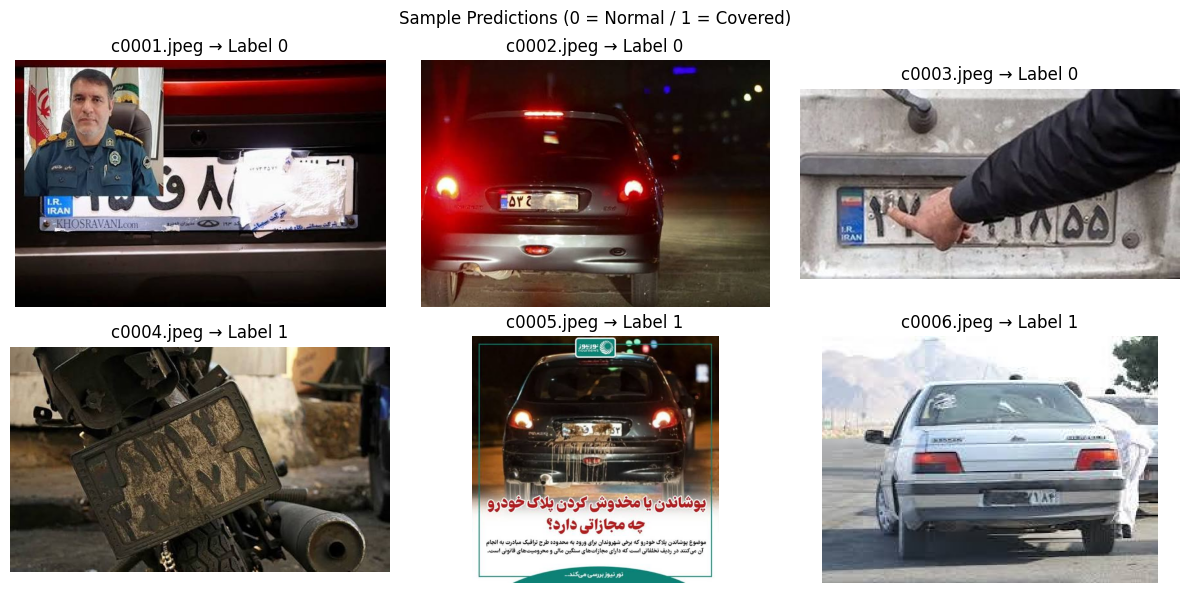

In [7]:
import cv2
import matplotlib.pyplot as plt

def show_sample_results(image_dir, output_txt, max_show=6):
    results = {}
    with open(output_txt, "r") as f:
        lines = f.readlines()[1:]
        for l in lines:
            name, lab = l.strip().split(",")
            results[name] = lab

    imgs = list(results.keys())[:max_show]

    plt.figure(figsize=(12, 6))
    for i, fn in enumerate(imgs, 1):
        img = cv2.imread(os.path.join(image_dir, fn))
        img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

        plt.subplot(2, 3, i)
        plt.imshow(img)
        plt.axis("off")
        plt.title(f"{fn} → Label {results[fn]}")

    plt.suptitle("Sample Predictions (0 = Normal / 1 = Covered)")
    plt.tight_layout()
    plt.show()

show_sample_results("/content/test_images", "/content/output.txt")


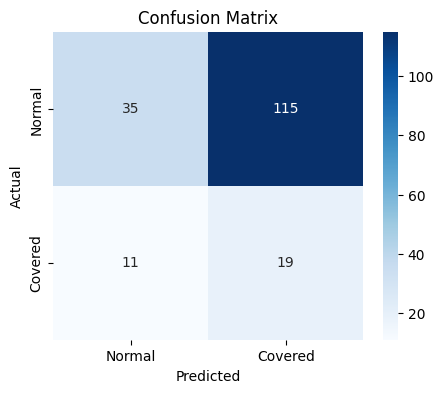

In [8]:
from sklearn.metrics import confusion_matrix
import seaborn as sns
import numpy as np

y_true = []
y_pred = []

covered_files = set(os.path.basename(p) for p in glob.glob("/content/dataset/cover/*"))

with open("/content/output.txt", "r") as f:
    for line in f.readlines()[1:]:
        fn, lab = line.strip().split(",")
        y_pred.append(int(lab))
        y_true.append(1 if fn in covered_files else 0)

cm = confusion_matrix(y_true, y_pred)

plt.figure(figsize=(5,4))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=["Normal", "Covered"],
            yticklabels=["Normal", "Covered"])
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix")
plt.show()

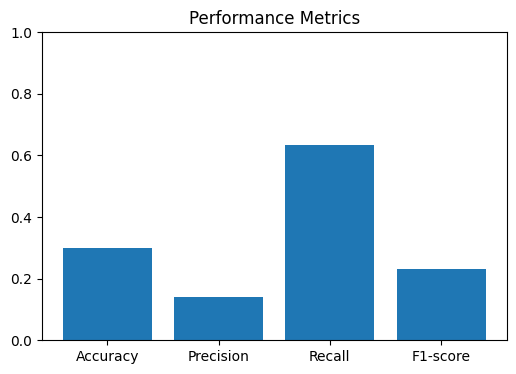

In [9]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

acc = accuracy_score(y_true, y_pred)
prec = precision_score(y_true, y_pred)
rec = recall_score(y_true, y_pred)
f1 = f1_score(y_true, y_pred)

metrics = [acc, prec, rec, f1]
labels = ["Accuracy", "Precision", "Recall", "F1-score"]

plt.figure(figsize=(6,4))
plt.bar(labels, metrics)
plt.ylim(0,1)
plt.title("Performance Metrics")
plt.show()


In [11]:
import shutil

shutil.make_archive("results", "zip", "results")

'/content/results.zip'

In [13]:
import shutil

shutil.make_archive("dataset", "zip", "dataset")


'/content/dataset.zip'